Dataset shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing values after preprocessing:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


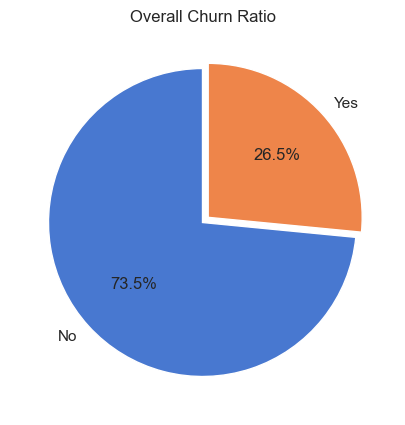

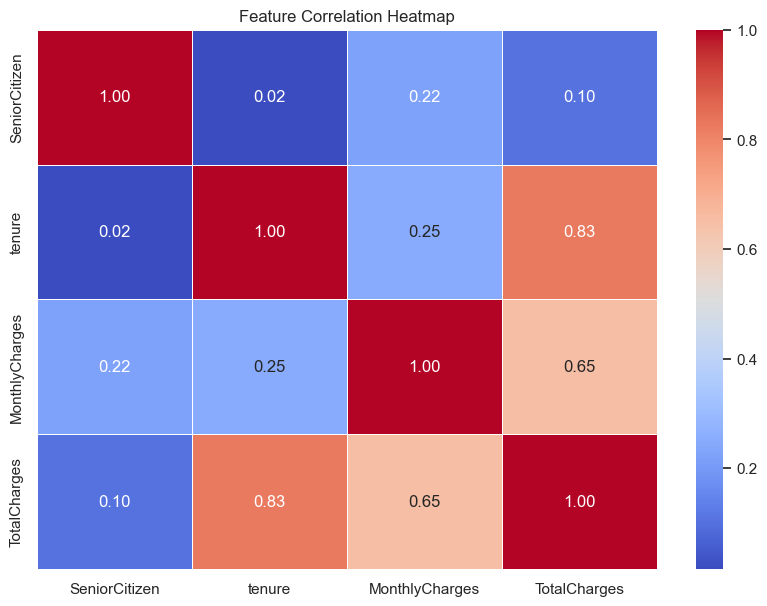

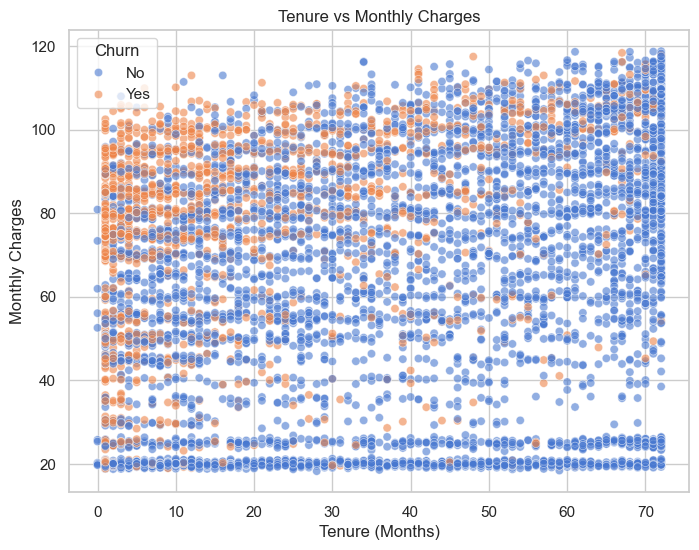

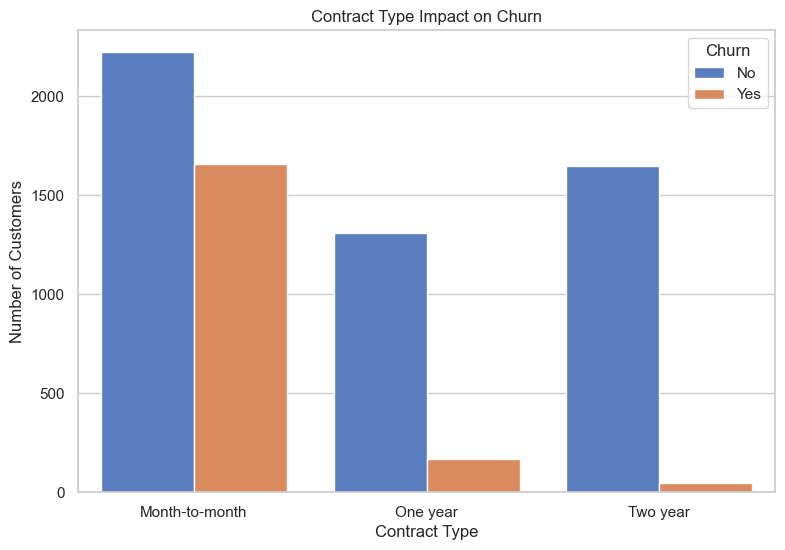


Feature shape: (7043, 19)
Target shape: (7043,)

Training samples: 5634
Testing samples: 1409


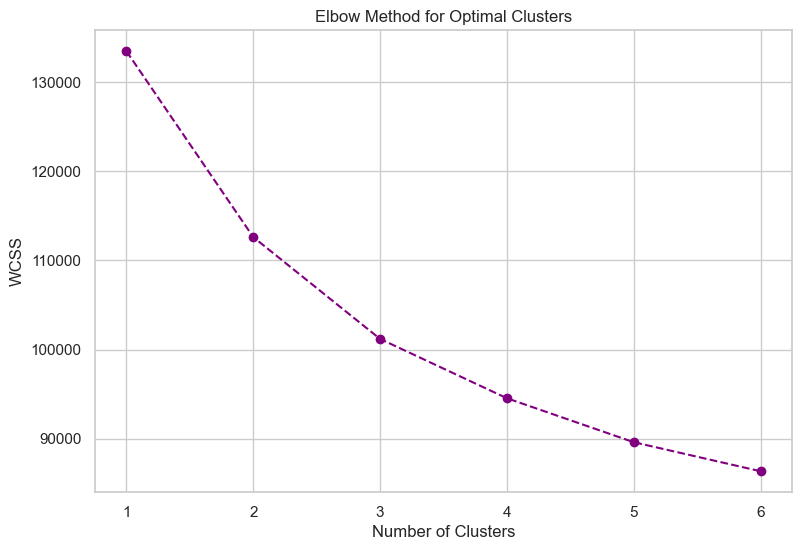

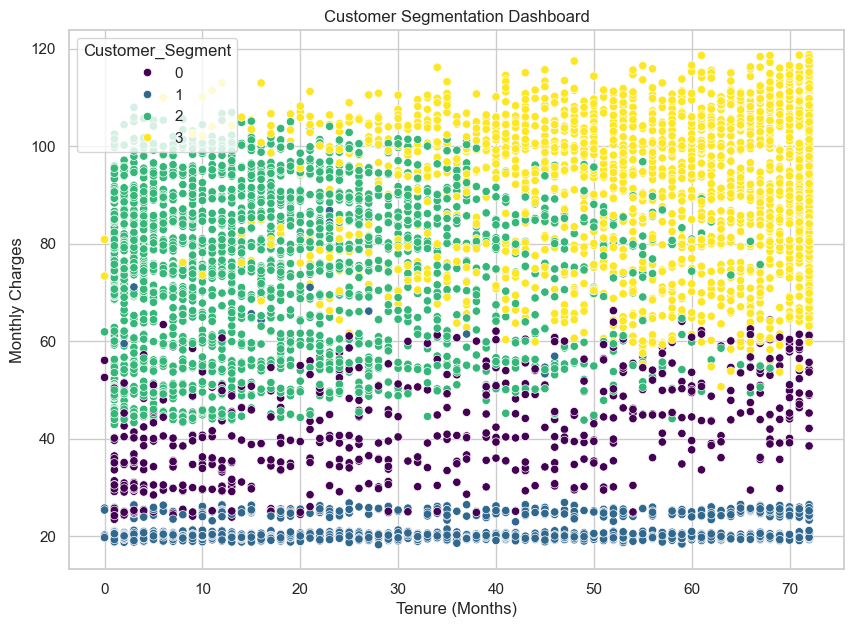


Best Random Forest Parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}

Model Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC Score: 0.8403


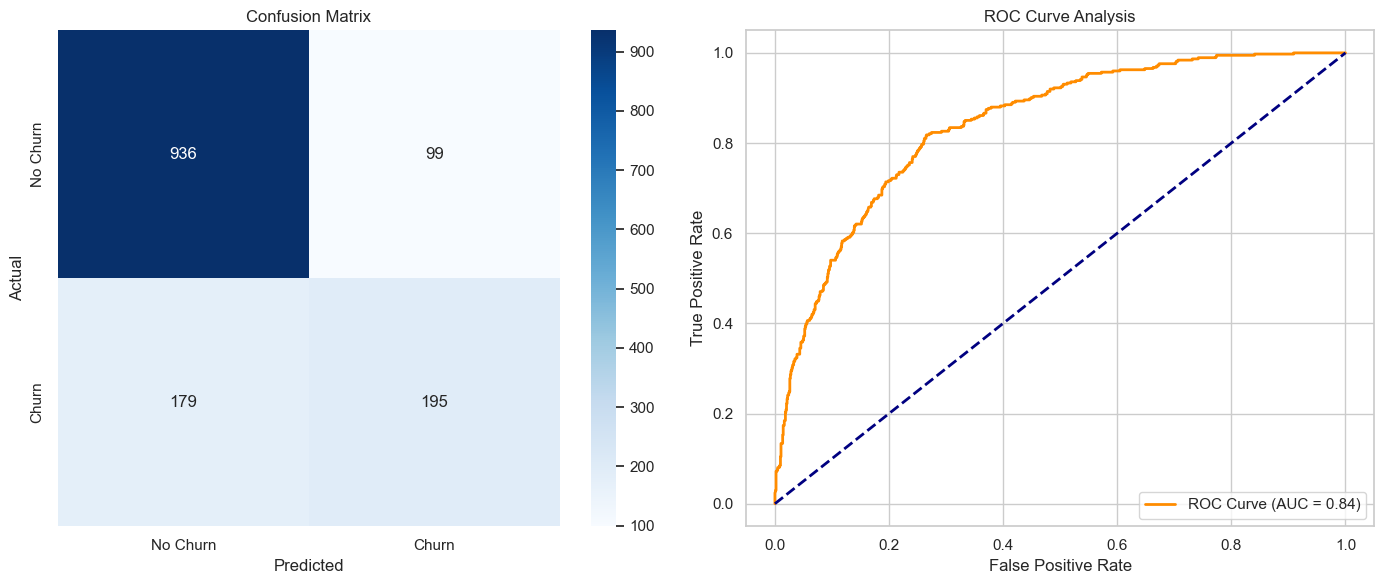

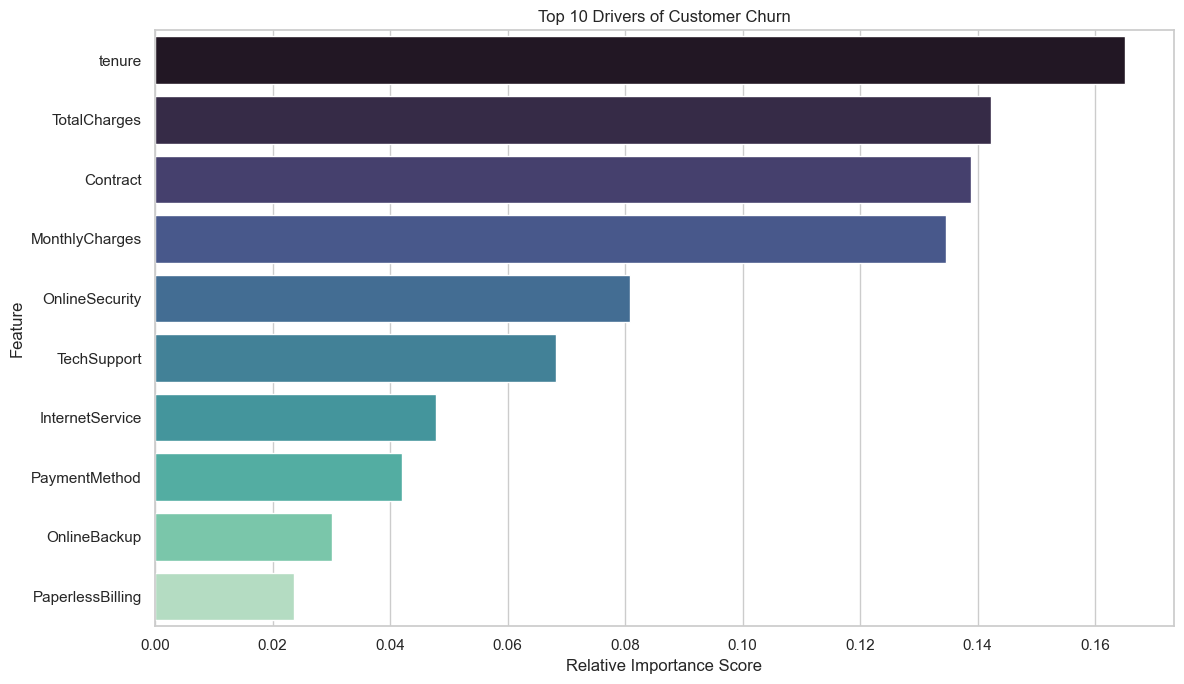


Customer Segment Summary:


,Customers,Average_Tenure,Average_MonthlyCharges,Average_TotalCharges,Churn_Rate
Customer_Segment,,,,,
0,662,30.53,41.33,1404.72,26.0
1,1546,30.46,21.72,681.45,7.0
2,2745,15.99,73.65,1194.37,46.0
3,2090,55.88,92.35,5172.03,15.0



Final Model Summary
Dataset size: 7043 customers
Features used: 19
Training samples: 5634
Testing samples: 1409
Number of clusters: 4
ROC-AUC Score: 0.8403


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')

# Load the actual Telco Customer Churn dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print('Dataset shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())

df.head()


# Data Preprocessing

# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Fill missing TotalCharges with median
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

# Drop customer ID
df.drop(columns=['customerID'], inplace=True)

print('\nMissing values after preprocessing:')
print(df.isnull().sum())


# Exploratory Data Analysis Dashboard

# Churn ratio
plt.figure(figsize=(7, 5))

df['Churn'].value_counts().plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    explode=(0, 0.05)
)

plt.title('Overall Churn Ratio')
plt.ylabel('')
plt.show()


# Feature correlation heatmap
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap')
plt.show()


# Tenure vs Monthly Charges
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    hue='Churn',
    alpha=0.6
)

plt.title('Tenure vs Monthly Charges')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')
plt.show()


# Contract type vs Churn
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Contract Type Impact on Churn')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()


# Categorical Encoding

categorical_cols = df.select_dtypes(
    include=['object']
).columns

label_encoders = {}

for col in categorical_cols:

    if col != 'Churn':

        le = LabelEncoder()

        df[col] = le.fit_transform(df[col])

        label_encoders[col] = le


# Encode Churn separately
le_churn = LabelEncoder()

df['Churn'] = le_churn.fit_transform(
    df['Churn']
)


# Separate features and target

X = df.drop(columns=['Churn'])
y = df['Churn']

print('\nFeature shape:', X.shape)
print('Target shape:', y.shape)


# Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('\nTraining samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])


# Scaling for Clustering

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_scaled = scaler.transform(X)


# Optimal K Search using Elbow Method

wcss = []

for i in range(1, 7):

    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 7),
    wcss,
    marker='o',
    linestyle='--',
    color='purple'
)

plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.xticks(range(1, 7))
plt.show()


# K-Means Clustering

kmeans_final = KMeans(
    n_clusters=4,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Customer_Segment'] = kmeans_final.fit_predict(
    X_scaled
)


# Customer Segmentation Visualization

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    hue='Customer_Segment',
    palette='viridis',
    legend='full'
)

plt.title('Customer Segmentation Dashboard')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')
plt.show()


# Random Forest Classifier

rf = RandomForestClassifier(
    random_state=42
)


# Random Forest Hyperparameter Tuning

param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

rf_tuned = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

rf_tuned.fit(
    X_train,
    y_train
)


# Best Model

best_model = rf_tuned.best_estimator_

print('\nBest Random Forest Parameters:')
print(rf_tuned.best_params_)


# Predictions

y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(
    X_test
)[:, 1]


# Model Evaluation

print('\nModel Classification Report:')

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn']
    )
)

auc_score = roc_auc_score(
    y_test,
    y_prob
)

print('ROC-AUC Score:', round(auc_score, 4))


# Performance Visualizations

plt.figure(figsize=(14, 6))


# Confusion Matrix

plt.subplot(1, 2, 1)

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')


# ROC Curve

plt.subplot(1, 2, 2)

fpr, tpr, _ = roc_curve(
    y_test,
    y_prob
)

plt.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f'ROC Curve (AUC = {auc_score:.2f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='navy',
    lw=2,
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Analysis')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()


# Feature Importance

importances = best_model.feature_importances_

indices = np.argsort(
    importances
)[::-1]

top_n = min(
    10,
    len(X.columns)
)


plt.figure(figsize=(12, 7))

sns.barplot(
    x=importances[indices][:top_n],
    y=X.columns[indices][:top_n],
    palette='mako'
)

plt.title('Top 10 Drivers of Customer Churn')
plt.xlabel('Relative Importance Score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


# Customer Segment Summary

segment_summary = df.groupby(
    'Customer_Segment'
).agg(
    Customers=('Customer_Segment', 'count'),
    Average_Tenure=('tenure', 'mean'),
    Average_MonthlyCharges=('MonthlyCharges', 'mean'),
    Average_TotalCharges=('TotalCharges', 'mean'),
    Churn_Rate=('Churn', 'mean')
).round(2)


segment_summary['Churn_Rate'] = (
    segment_summary['Churn_Rate'] * 100
).round(2)


print('\nCustomer Segment Summary:')

display(segment_summary)


# Final Model Summary

print('\nFinal Model Summary')

print(
    'Dataset size:',
    df.shape[0],
    'customers'
)

print(
    'Features used:',
    X.shape[1]
)

print(
    'Training samples:',
    X_train.shape[0]
)

print(
    'Testing samples:',
    X_test.shape[0]
)

print(
    'Number of clusters: 4'
)

print(
    'ROC-AUC Score:',
    round(auc_score, 4)
)